In [26]:
import numpy as np
import pandas as pd
import os
import s3fs
import sys
import cartiflette #Attention, cartiflette n'est pas disponible par défaut sur Onyxia
sys.path.append('../outils')

import fonctions_nomenclature as fnom
import fonctions_preparation_table as fprep
%load_ext autoreload
%autoreload 2

np.random.seed(123)

# Create filesystem object
S3_ENDPOINT_URL = "https://" + os.environ["AWS_S3_ENDPOINT"]
fs = s3fs.S3FileSystem(client_kwargs={'endpoint_url': S3_ENDPOINT_URL})
BUCKET = "mathildedonnenfeld/diffusion/bistrots_et_bulletins"


FILE_KEY_S3 = "table_analyse_muni.csv"
FILE_PATH_S3 = BUCKET + "/" + FILE_KEY_S3

with fs.open(FILE_PATH_S3, mode="rb") as file_in:
    df = pd.read_csv(file_in, sep=",")

df.head()   

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


/tmp/ipykernel_115247/4032096808.py:26: DtypeWarning: Columns (2: CODGEO, 7: dep, 8: code_commune, 11: Code commune) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_in, sep=",")


,Unnamed: 0.1,Unnamed: 0,CODGEO,LIBGEO,POPULATION,NIVVIE_MEDIAN,TAUX_PAUVRETE,dep,code_commune,nb_etablissements,...,Libellé commune,Nombre candidats,ind1,ind2,ind3,ind4,part_votes_liste_gagnante,Abstentions,Exprimés,tour
0,0,0,01001,L'Abergement-Clémenciat,860,28270.0,NaN,01,01001,1.0,...,L'Abergement-Clémenciat,1.0,2.0,2.0,2.0,2.0,1.0000,305.0,345.0,1.0
1,1,1,01002,L'Abergement-de-Varey,270,28140.0,NaN,01,NaN,NaN,...,L'Abergement-de-Varey,2.0,2.0,2.0,2.0,2.0,0.5588,40.0,204.0,1.0
2,2,2,01004,Ambérieu-en-Bugey,15934,24210.0,18.0,01,01004,10.0,...,Ambérieu-en-Bugey,3.0,0.0,0.0,0.0,0.0,0.5415,4520.0,4081.0,1.0
3,3,3,01005,Ambérieux-en-Dombes,1906,28120.0,5.0,01,01005,1.0,...,Ambérieux-en-Dombes,1.0,2.0,2.0,2.0,2.0,1.0000,770.0,526.0,1.0
4,4,4,01006,Ambléon,115,NaN,NaN,01,NaN,NaN,...,Ambléon,2.0,2.0,2.0,2.0,2.0,0.7778,14.0,90.0,1.0


In [9]:
df.columns

Index(['Unnamed: 0.1', 'Unnamed: 0', 'CODGEO', 'LIBGEO', 'POPULATION',
       'NIVVIE_MEDIAN', 'TAUX_PAUVRETE', 'dep', 'code_commune',
       'nb_etablissements', 'age_moyen_bistrots', 'Code commune',
       'Libellé commune', 'Nombre candidats', 'ind1', 'ind2', 'ind3', 'ind4',
       'part_votes_liste_gagnante', 'Abstentions', 'Exprimés', 'tour'],
      dtype='str')

In [5]:
# Modélisation simple, paramètres fixés

# Il va dans un seul bistrot par ville
nb_bistrots_par_ville = 1

# Dans 1000 bistrots au total
nb_bistrots_total = 1000

# On sélectionne donc les 1000 premières villes
nombre_villes = nb_bistrots_total/nb_bistrots_par_ville

# Paramètre de la stratégie de classement selon le nombre de bistrots 
croissant = True

# On crée la sous-table qui contient ces villes 
bistrots_visites = df.sort_values("nb_etablissements", ascending=croissant).head(int(nombre_villes)) #Arrondi à l'inférieur

# On calcule la proportion du nombre de bistrots visités dans la ville par rapport au nombre de bistrots totaux de la ville
bistrots_visites['part_des_etablissements_visites'] = nb_bistrots_par_ville/bistrots_visites['nb_etablissements']

# On applique cette proportion aux abstentionnistes de la ville
bistrots_visites['voix_pour_attal'] = bistrots_visites['part_des_etablissements_visites']*bistrots_visites['Abstentions']

# On calcule le nombre de voix obtenues par la liste gagnante
bistrots_visites['voix_LG'] = bistrots_visites['part_votes_liste_gagnante']*bistrots_visites['Exprimés']

# Indicatrice de victoire 
bistrots_visites['victoire_attal'] =  bistrots_visites['voix_pour_attal'] > bistrots_visites['voix_LG']

codes_communes_gagnees = bistrots_visites[bistrots_visites['victoire_attal']==True].CODGEO

decompte_communes = (bistrots_visites['victoire_attal'] == True).sum()
part_communes = decompte_communes / bistrots_visites.shape[0]

print(f"Gabriel Attal a emporté {decompte_communes} communes grâce à ses visites, "
      f"soit {part_communes:.1%} des communes visitées ! Bravo !")


Gabriel Attal a emporté 308 communes grâce à ses visites, soit 30.8% des communes visitées ! Bravo !


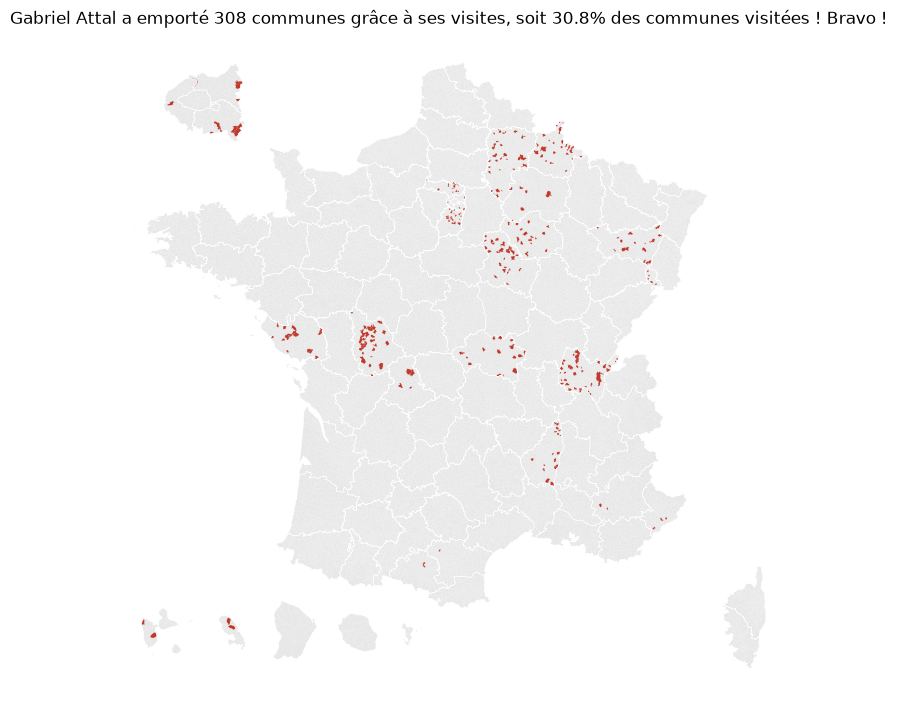

In [ ]:
# Partie carto codée avec Claude Code
import matplotlib.pyplot as plt
from cartiflette import carti_download   # versions anciennes : from cartiflette.client import carti_download

# Fond de carte : communes de France, DROM rapprochés
communes = carti_download(
    values=["France"],
    crs=4326,
    borders="COMMUNE_ARRONDISSEMENT",
    vectorfile_format="parquet",   
    simplification=50,
    filter_by="FRANCE_ENTIERE_DROM_RAPPROCHES",
    source="EXPRESS-COG-CARTO-TERRITOIRE",
    year=2025,
)

# Départements, pour avoir des repères sur la carte
departements = carti_download(
    values=["France"],
    crs=4326,
    borders="DEPARTEMENT",
    vectorfile_format="parquet",
    simplification=50,
    filter_by="FRANCE_ENTIERE_DROM_RAPPROCHES",
    source="EXPRESS-COG-CARTO-TERRITOIRE",
    year=2025,
)


codes = [str(c).zfill(5) for c in codes_communes_gagnees]
communes["selection"] = communes["INSEE_COG"].isin(codes)

fig, ax = plt.subplots(figsize=(9, 9))
communes.plot(ax=ax, color="#e8e8e8", linewidth=0)
communes[communes["selection"]].plot(ax=ax, color="#c0392b", linewidth=0)
departements.boundary.plot(ax=ax, color="white", linewidth=0.4)
ax.set_axis_off()
ax.set_title(f"Gabriel Attal a emporté {decompte_communes} communes grâce à ses visites, "
      f"soit {part_communes:.1%} des communes visitées ! Bravo !")
plt.show()

In [ ]:
# On enregistre les fonds de cartiflette pour ne pas en avoir besoin dans le qmd

FILE_KEY_OUT_S3 = "communes_2025.parquet"
FILE_PATH_OUT_S3 = BUCKET + "/" + FILE_KEY_OUT_S3

with fs.open(FILE_PATH_OUT_S3, 'wb') as file_out:
    communes.to_parquet(file_out)

In [27]:
df.nb_etablissements.describe()

count    11763.000000
mean         4.151067
std         32.652828
min          1.000000
25%          1.000000
50%          1.000000
75%          3.000000
max       3084.000000
Name: nb_etablissements, dtype: float64

In [12]:
FILE_KEY_OUT_S3 = "departements_2025.parquet"
FILE_PATH_OUT_S3 = BUCKET + "/" + FILE_KEY_OUT_S3

with fs.open(FILE_PATH_OUT_S3, 'wb') as file_out:
    departements.to_parquet(file_out)

In [ ]:
# Modélisation plus complexe (à transformer en version interactive ?)

#Paramètres à fixer :

# Nb de bistrots par ville

#Nb de bistrots complet

# Stratégie aggressive ou passive (taux appliqué aux abstentionnistes ou volé à la LG)

#Efficacité décroissante avec le nombre de bistrots visités

# Sélection des bistrots (par ordre croissant ou décroissant de nb de bistrots, de revenu médian, de taux de pauvreté, de % de la LG, Abstentions, Population, filtrage des tours...)


In [44]:
nb_bistrots_total

1000

In [45]:
xs

array([0.64813431])

In [46]:
max((nb_bistrots_total-1000), 0)

0

In [51]:
efficacite = 1-(max((1200-1000), 0)/1000*xs)
print(efficacite) 

[0.87037314]


In [54]:
from scipy.stats import truncnorm
rng = np.random.default_rng(seed=42)
mu, sigma = 0.5, 0.2               # choisis ton écart-type
a, b = (0 - mu) / sigma, (1 - mu) / sigma   # bornes exprimées en écarts-types
xs = truncnorm.rvs(a, b, loc=mu, scale=sigma, size=1, random_state=rng)
xs

array([0.64813431])

In [57]:
efficacite = 1-(max((nb_bistrots_total-1000), 0)/1000*xs)
print(efficacite) 

[1.]


[-4.83320882]
count    29.000000
mean      0.050278
std       0.022387
min       0.003243
25%       0.033670
50%       0.053476
75%       0.062500
max       0.085470
Name: part_des_etablissements_visites, dtype: float64
count       29.000000
mean    -12014.777819
std       3530.121279
min     -19633.606895
25%     -13732.797965
50%     -11564.088043
75%      -9852.036574
max      -6473.378143
Name: voix_pour_attal, dtype: float64
count        29.000000
mean      51453.891052
std       79447.817992
min       14077.897200
25%       20741.568000
50%       26623.710600
75%       38668.778100
max      428122.646400
Name: voix_LG, dtype: float64


/opt/python/lib/python3.13/site-packages/geopandas/plotting.py:1408: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  return plot_dataframe(data, *args, **kwargs)


Text(0.5, 1.0, 'Gabriel Attal a emporté 0 communes grâce à ses visites, soit 0.0% des communes visitées ! Bravo !')

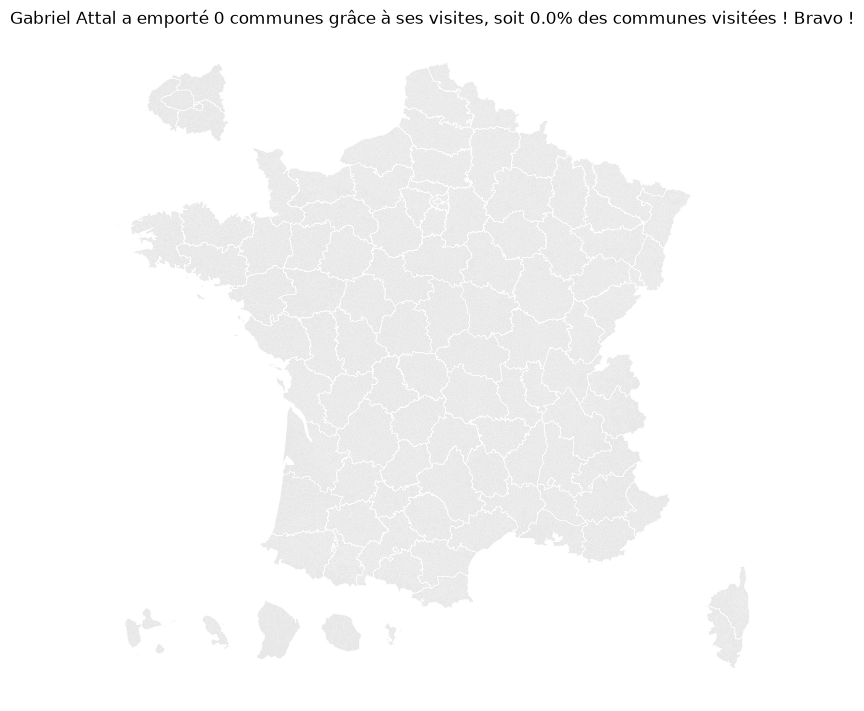

In [61]:



def calcul_codes(nb_bistrots_par_ville = 1, nb_bistrots_total = 2000, critere_tri="nb_etablissements", croissant=False, tour="tous"):
    

    bistrots_ordonnes = df.sort_values(critere_tri, ascending=croissant)
    cumul = bistrots_ordonnes["nb_etablissements"].cumsum()
    bistrots_visites = bistrots_ordonnes[cumul.shift(fill_value=0) < nb_bistrots_total]
    
    efficacite = 1-(max((nb_bistrots_total-1000), 0)/1000*xs)
    print(efficacite)       

    bistrots_visites['part_des_etablissements_visites'] = (nb_bistrots_par_ville / bistrots_visites['nb_etablissements']).clip(upper=1)
    print(bistrots_visites['part_des_etablissements_visites'].describe())
    bistrots_visites['voix_pour_attal'] = bistrots_visites['part_des_etablissements_visites'] * bistrots_visites['Abstentions'] * efficacite
    print(bistrots_visites['voix_pour_attal'].describe())
    bistrots_visites['voix_LG'] = bistrots_visites['part_votes_liste_gagnante'] * bistrots_visites['Exprimés']
    print(bistrots_visites['voix_LG'].describe())
    bistrots_visites['victoire_attal'] = bistrots_visites['voix_pour_attal'] > bistrots_visites['voix_LG']

    codes_communes_gagnees = bistrots_visites.loc[bistrots_visites['victoire_attal'], 'CODGEO']
    decompte_communes = int(bistrots_visites['victoire_attal'].sum())
    part_communes = decompte_communes / bistrots_visites.shape[0]

    return codes_communes_gagnees, decompte_communes, part_communes 

codes_gagnees, decompte, part = calcul_codes(10, 10000)

codes = [str(c).zfill(5) for c in codes_gagnees]
communes["selection"] = communes["INSEE_COG"].isin(codes)

fig, ax = plt.subplots(figsize=(9, 9))
communes.plot(ax=ax, color="#e8e8e8", linewidth=0)
communes[communes["selection"]].plot(ax=ax, color="#de7e20", linewidth=0)
departements.boundary.plot(ax=ax, color="white", linewidth=0.4)
ax.set_axis_off()
ax.set_title(f"Gabriel Attal a emporté {decompte} communes grâce à ses visites, "
      f"soit {part:.1%} des communes visitées ! Bravo !")
#plt.show()